# Efficient Frontier & Factor Exposure-Based Stock Selection
**Economia Finanziaria — Modulo 2** | Scadenza: 15 Maggio 2026

---

## Obiettivo del Notebook

L'obiettivo di questo notebook è costruire e valutare una strategia di investimento sistematica basata sull'universo azionario europeo dello STOXX 600.

L'idea di fondo è che le esposizioni ai fattori di rischio — in particolare l'esposizione al mercato (beta) e al momentum — contengano informazioni utili per selezionare titoli con caratteristiche di rischio/rendimento distinte. 
Anziché scegliere i titoli soggettivamente, li classifichiamo in modo quantitativo in base a queste esposizioni e costruiamo portafogli ottimizzati per ciascun gruppo.

Il processo si articola in tre fasi principali:

1. **Selezione** — Campioniamo 150 titoli dallo STOXX 600, stimiamo il modello di Carhart per ciascuno e li classifichiamo tramite un doppio ordinamento su beta di mercato e momentum.
2. **Ottimizzazione** — Per due gruppi contrapposti costruiamo il portafoglio tangente (Tangency Portfolio), che massimizza il rapporto rendimento/rischio, usando esclusivamente i dati storici del periodo In-Sample.
3. **Valutazione** — Applichiamo i pesi ottimali al periodo Out-of-Sample e confrontiamo le performance dei due portafogli con il benchmark ETF EXSA.DE, per verificare se il posizionamento fattoriale ha generato valore rispetto al mercato.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import quantstats as qs
import fmfinance as fm
import statsmodels.stats.api as sms
import statsmodels.api as sm
import ipywidgets as widgets
import requests
import random
import time
import warnings

from statsmodels.compat import lzip
from statsmodels.regression.rolling import RollingOLS
from statsmodels.datasets import longley
from statsmodels.iolib.summary2 import summary_col
from scipy.stats import norm
from scipy import stats
from datetime import datetime
from pandas.plotting import register_matplotlib_converters
from pypfopt import EfficientFrontier
from pypfopt import risk_models
from pypfopt import expected_returns
from bs4 import BeautifulSoup
from io import StringIO

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_rows', 20)

---
## PUNTO 1 — Campionamento, download rendimenti e fattori di Carhart

**Obiettivo:** Costruire il dataset di partenza. Partiamo dall'universo dello STOXX 600, estraiamo un campione casuale di 150 titoli e scarichiamo i loro prezzi storici mensili. 
Da questi ricaviamo i rendimenti percentuali mensili e puliamo il campione eliminando i titoli con storico insufficiente. 
In parallelo scarichiamo i quattro fattori del modello di Carhart (mercato, SMB, HML, momentum) e il tasso risk-free, che useremo nelle regressioni successive.


In [2]:
stoxx600 = pd.read_excel('stoxx600.xlsx', header=0)

start = '2019-01-01'
end   = '2025-12-31'

# Campionamento casuale di 150 titoli — seed obbligatorio: 12345
random.seed(12345)
random_tickers = random.sample(list(stoxx600['Tickers']), 150)

# Download prezzi mensili
prices = yf.download(
    random_tickers,
    start=start, end=end,
    auto_adjust=False,
    multi_level_index=False,
    interval='1mo'
)['Adj Close']

# Calcolo rendimenti percentuali mensili
# Pulizia: thresh=48 mantiene solo i titoli con almeno 48 osservazioni IS
# dropna(axis=0) rimuove le righe iniziali con NaN da pct_change()
rendimenti_grezzi       = prices.pct_change() * 100
returns = rendimenti_grezzi.dropna(axis=1, thresh=48).dropna(axis=0)

# Download fattori Fama-French mensili (Mkt-RF, SMB, HML) + Risk-Free
factors = fm.ff('F-F_Research_Data_Factors', start, end)[0]

# Download fattore Momentum mensile
mom     = fm.ff('F-F_Momentum_Factor', start, end)[0]

# Dataset Carhart a 4 fattori
ff4f    = pd.concat([factors[['Mkt-RF', 'SMB', 'HML']], mom], axis=1)

# Risk-free rate mensile
rf      = factors['RF']

[*****************     35%                       ]  53 of 150 completed$CSG.AS: possibly delisted; no price data found  (1mo 2019-01-01 -> 2025-12-31) (Yahoo error = "Data doesn't exist for startDate = 1546297200, endDate = 1767135600")
[**********************98%********************** ]  147 of 150 completed$EBP.WA: possibly delisted; no price data found  (1mo 2019-01-01 -> 2025-12-31) (Yahoo error = "Data doesn't exist for startDate = 1546297200, endDate = 1767135600")
[*********************100%***********************]  150 of 150 completed

2 Failed downloads:
['CSG.AS', 'EBP.WA']: possibly delisted; no price data found  (1mo 2019-01-01 -> 2025-12-31) (Yahoo error = "Data doesn't exist for startDate = 1546297200, endDate = 1767135600")


In [3]:
display(ff4f.tail(5))
display(prices)

,Mkt-RF,SMB,HML,Mom
Date,,,,
2025-08-01,1.84,3.80,4.46,-3.60
2025-09-01,3.39,-1.90,-0.94,4.63
2025-10-01,1.96,-0.82,-2.80,0.33
2025-11-01,-0.13,0.54,3.57,-1.79
2025-12-01,-0.36,-1.03,2.36,-2.33


Ticker,A2A.MI,AAL.L,ABBN.SW,ACLN.SW,ACS.MC,ADYEN.AS,AENA.MC,AIXA.DE,AKZA.AS,ALLN.SW,...,TSCO.L,UMI.BR,UPM.HE,UU.L,VIS.MC,VOD.L,VOW3.DE,WIE.VI,WRT1V.HE,ZAB.WA
Date,,,,,,,,,,,,,,,,,,,,,
2019-01-01,1.108216,1889.982300,14.464811,NaN,22.701580,647.700012,12.262001,8.183819,50.294533,118.837074,...,281.175140,30.081280,17.414040,828.188538,36.968658,137.934067,89.287941,15.637007,11.140606,NaN
2019-02-01,1.084548,1949.032227,15.082932,NaN,24.832649,660.000000,12.758010,7.388379,60.409760,118.321037,...,284.829956,31.020035,18.282677,837.559204,39.028385,133.654129,90.657715,15.876345,11.183681,NaN
2019-03-01,1.132232,1997.672852,14.323634,NaN,24.947319,698.000000,13.050736,7.533176,63.313473,125.250740,...,292.517883,32.317993,17.924191,811.840271,42.372585,139.148376,84.301476,15.102474,11.265913,NaN
2019-04-01,1.037212,1927.965088,16.002485,NaN,26.074919,725.599976,13.445105,9.637425,60.676399,119.869179,...,314.825378,28.162939,17.310635,826.195007,40.700485,141.338150,93.144951,16.323118,11.330584,NaN
2019-05-01,1.015981,1843.895142,14.022208,NaN,23.507561,720.799988,14.000104,8.146210,61.678619,125.354668,...,285.334137,22.049915,16.201735,794.893799,35.342155,128.816803,83.808823,15.413622,10.426208,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08-01,2.148000,2277.863770,52.897202,67.615837,64.235008,1434.400024,23.699623,12.498532,56.847496,175.486481,...,422.565948,13.003132,22.896309,1149.829102,58.126724,88.341217,100.250000,28.633627,24.247658,21.799999
2025-09-01,2.227000,2784.900391,56.484119,65.797676,67.668167,1365.000000,22.291439,14.936419,58.389122,180.522522,...,445.358704,14.728434,21.898773,1146.329590,56.474293,86.141685,91.760002,26.382193,24.644684,23.450001
2025-10-01,2.526000,2874.897217,58.789997,64.667473,70.852547,1488.599976,22.559664,13.834634,55.344406,186.139633,...,459.254303,16.122324,21.908182,1200.321533,52.391815,92.120407,90.220001,24.765778,27.702969,21.450001


---
## PUNTO 2 — Split In-Sample / Out-of-Sample

| Periodo | Date |
|---|---|
| **In-Sample** | Gennaio 2019 → Dicembre 2022 |
| **Out-of-Sample** | Gennaio 2023 → Dicembre 2025 |

&nbsp;

> **Obiettivo:** Separare il dataset in due periodi temporali distinti. Il periodo In-Sample è quello che usiamo per "imparare" — stimare i beta e ottimizzare i portafogli. 
Il periodo Out-of-Sample è quello che teniamo nascosto fino alla fine, usato solo per valutare se la strategia funziona davvero su dati mai visti. 
Questo approccio evita il cosiddetto *look-ahead bias*: non vogliamo che le scelte di portafoglio vengano influenzate da informazioni future che un investitore reale non avrebbe avuto a disposizione.
Le stime del modello di Carhart e la classificazione dei titoli vengono eseguite **esclusivamente sul periodo In-Sample**.


In [4]:
# Uniformiamo il formato delle date
# yfinance e fmfinance restituiscono indici con formati diversi:
# to_period('M').to_timestamp() li porta entrambi allo stesso standard
returns.index = pd.to_datetime(returns.index).to_period('M').to_timestamp()
ff4f.index   = pd.to_datetime(ff4f.index).to_period('M').to_timestamp()
rf.index          = pd.to_datetime(rf.index).to_period('M').to_timestamp()

# Rendimenti in eccesso: r_i - tasso_rf per ogni titolo
exc_returns = returns.subtract(rf, axis=0)

# Uniamo fattori e rendimenti in eccesso tenendo solo le date comuni
ds_completo = pd.concat([ff4f, exc_returns], axis=1).dropna()
split = ds_completo.index.searchsorted('2022-12-30')

# Split In-Sample / Out-of-Sample
df_in  = ds_completo.iloc[:split]
df_out = ds_completo.iloc[split:]

In [5]:
print('\nIN-SAMPLE')
display(df_in)

print('\nOUT-OF-SAMPLE')
display(df_out)


IN-SAMPLE


,Mkt-RF,SMB,HML,Mom,A2A.MI,AAL.L,ABBN.SW,ACS.MC,ADYEN.AS,AENA.MC,...,TRYG.CO,TSCO.L,UMI.BR,UPM.HE,UU.L,VIS.MC,VOD.L,VOW3.DE,WIE.VI,WRT1V.HE
Date,,,,,,,,,,,,,,,,,,,,,
2020-12-01,4.63,5.01,-1.68,-2.37,2.063535,9.522405,3.077192,2.481493,18.903858,4.089567,...,9.119327,1.928306,4.568099,10.308604,-0.609730,-2.446966,-2.225381,7.829250,12.210331,3.390147
2021-01-01,-0.07,7.14,3.22,4.31,2.721371,-0.433083,6.596520,-5.267031,-9.737533,-10.478200,...,-0.364389,3.457237,19.037930,-3.216271,3.054680,2.589990,3.256159,2.637445,7.515333,-0.539849
2021-02-01,2.81,2.02,7.20,-7.96,4.067145,14.850874,-0.835235,0.180456,11.427741,10.683426,...,2.262700,-25.867268,4.041062,7.154963,-6.831486,0.085908,-2.258893,10.598324,-1.283872,17.221789
2021-03-01,3.17,-2.33,7.35,-6.16,11.294387,2.524802,9.341504,11.523292,-0.652401,-1.845271,...,-0.918227,2.017558,-7.048927,-3.069612,7.751400,1.115888,8.080640,37.903134,12.716753,-5.977686
2021-04-01,4.95,-3.19,-1.02,1.23,4.832466,8.025934,6.858993,-3.998600,7.249803,4.627620,...,-5.381001,-3.430192,11.784230,10.649853,4.579831,-3.395590,3.730675,-9.178548,4.551275,21.445985
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-08-01,-3.77,1.41,0.18,1.98,-11.057833,-5.851018,-6.446517,1.269222,-11.651318,-0.718455,...,0.956281,-5.483230,-10.399278,9.521890,-3.263396,-1.947468,-4.428410,3.335130,3.820708,-3.863376
2022-09-01,-9.34,-0.76,0.03,3.71,-10.882275,-1.855374,-4.528140,4.183915,-15.931097,-12.817711,...,-6.602140,-17.037605,-4.604497,-4.055444,-16.063156,-0.190000,-12.776447,-11.263584,-11.929505,-20.253164
2022-10-01,7.85,0.01,7.97,3.91,11.992441,-4.872676,12.254821,11.961963,11.353955,11.229313,...,3.689676,3.783542,10.457020,3.852264,5.463059,7.551739,0.284227,2.095934,12.100082,6.451889



OUT-OF-SAMPLE


,Mkt-RF,SMB,HML,Mom,A2A.MI,AAL.L,ABBN.SW,ACS.MC,ADYEN.AS,AENA.MC,...,TRYG.CO,TSCO.L,UMI.BR,UPM.HE,UU.L,VIS.MC,VOD.L,VOW3.DE,WIE.VI,WRT1V.HE
Date,,,,,,,,,,,,,,,,,,,,,
2023-01-01,6.61,5.01,-3.94,-16.21,10.413062,6.756459,12.800396,1.032140,6.573312,16.870802,...,-5.702300,9.328865,0.553268,-5.159616,6.383668,0.153489,10.191345,26.376335,21.547164,10.478672
2023-02-01,-2.57,1.05,-0.80,0.54,0.856514,-17.129278,-1.820316,7.120892,-2.691918,6.132737,...,0.319618,3.360698,-9.176268,2.847987,-4.120714,2.111390,6.812050,1.408858,6.859993,4.659994
2023-03-01,2.48,-5.48,-9.05,-2.35,4.978599,-7.518953,-0.072283,2.047528,8.114577,1.347637,...,-4.239486,3.836058,-1.500335,-10.153082,3.765736,8.550900,-10.863112,-3.085306,-9.993643,-5.471387
2023-04-01,0.62,-3.37,-0.12,1.75,8.493523,-9.026082,5.011743,5.953241,-0.843418,2.336368,...,6.054296,5.446023,-4.995944,-6.973583,1.725454,-6.107582,7.040830,-1.910017,2.127464,22.298248
2023-05-01,0.34,1.60,-7.79,-0.86,-3.609997,-9.419283,3.189199,-0.616411,4.791519,-4.741938,...,0.190375,-7.581628,-12.994403,-0.755056,-6.783269,0.122311,-20.724969,-6.100616,-3.510175,0.497141
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08-01,1.84,3.80,4.46,-3.60,0.323240,5.672140,-0.081049,9.390141,-5.424350,4.472729,...,7.243352,-1.014700,-4.752753,6.565050,1.615570,-0.713335,7.349834,8.445442,0.433010,2.920336
2025-09-01,3.39,-1.90,-0.94,4.63,3.347840,21.929304,6.450922,5.014685,-5.168262,-6.271799,...,-4.203669,5.063893,12.938355,-4.686753,-0.634351,-3.172809,-2.819814,-8.798826,-8.192903,1.307379
2025-10-01,1.96,-0.82,-2.80,0.33,13.056135,2.861599,3.712347,4.335875,8.684943,0.833263,...,-1.361938,2.750092,9.093942,-0.327034,4.339984,-7.598913,6.570567,-2.048292,-6.496917,12.039511


---
## PUNTO 3 — Regressione di Carhart e costruzione del DataFrame di selezione

> **Obiettivo:** Misurare quanto ogni titolo è "esposto" ai fattori di rischio sistematici. Per ogni titolo stimiamo il modello di Carhart a 4 fattori sul periodo In-Sample: 
questo ci restituisce, per ciascun titolo, un coefficiente che misura la sensibilità al mercato (β_Mkt) e uno che misura la sensibilità al momentum (β_Mom). 
Questi due coefficienti diventano le variabili di classificazione che useremo nel passo successivo per ordinare e raggruppare i titoli. 
Infine, escludiamo i titoli con un beta di mercato negativo o nullo, che sarebbero economicamente anomali per un'azione ordinaria.

Per ogni titolo stimiamo il modello a 4 fattori di Carhart **esclusivamente sul periodo In-Sample**:

$$r_i - r_f = \alpha + \beta_{Mkt}(r_m - r_f) + \beta_{SMB} \cdot SMB + \beta_{HML} \cdot HML + \beta_{Mom} \cdot Mom + \varepsilon_i$$

Salviamo i coefficienti $\hat{\beta}_{Mkt}$ e $\hat{\beta}_{Mom}$ in un DataFrame per il doppio ordinamento.


In [16]:
# Regressori Carhart IS
regressori = df_in[['Mkt-RF', 'SMB', 'HML', 'Mom']]
regressori_costante  = sm.add_constant(regressori)
variabili_dipendenti  = df_in[exc_returns.columns]

# Ciclo di regressione — salviamo tutti i risultati in una lista
risultati_regressioni = []
for col in variabili_dipendenti.columns:
    risultati_regressioni.append(sm.OLS(variabili_dipendenti[col], regressori_costante).fit())

summary_col(risultati_regressioni,stars=True)

,A2A.MI,AAL.L,ABBN.SW,ACS.MC,ADYEN.AS,AENA.MC,AIXA.DE,AKZA.AS,ALLN.SW,ALO.PA,AM.PA,ANDR.VI,ARGX.BR,AZM.MI,AZN.L,BAER.SW,BAMI.MI,BBVA.MC,BBY.L,BCVN.SW,BESI.AS,BKG.L,BKT.MC,BMED.MI,BP.L,COV.PA,CRDA.L,CS.PA,DGE.L,DKSH.SW,DNB.OL,DNP.WA,DPLM.L,DSV.CO,ENEL.MI,ENGI.PA,ENR.DE,EOAN.DE,EPI-A.ST,EVD.DE,EVK.DE,FBK.MI,FGR.PA,FLS.CO,FME.DE,FTK.DE,G1A.DE,GAW.L,GBF.DE,GLEN.L,GMAB.CO,HEI.DE,HEIO.AS,HER.MI,HEXA-B.ST,HSBA.L,HSX.L,HUBN.SW,HUH1V.HE,IDR.MC,IGG.L,III.L,IMB.L,IMI.L,INDU-C.ST,INF.L,INGA.AS,INVE-B.ST,INVP.L,ITV.L,JD.L,JMAT.L,KBCA.BR,KCR.HE,KEMIRA.HE,KER.PA,KESKOB.HE,KPN.AS,LAGR-B.ST,LHA.DE,LISP.SW,LMP.L,LOTB.BR,LR.PA,LUND-B.ST,ML.PA,MONC.MI,MRL.MC,MUV2.DE,NDA.DE,NDX1.DE,NESTE.HE,OR.PA,ORA.PA,PAF.L,PHIA.AS,PKN.WA,PRU.L,PSON.L,PSPN.SW,PST.MI,PZU.WA,RAA.DE,RAND.AS,RBREW.CO,RI.PA,RKT.L,ROCK-B.CO,RS1.L,RTO.L,RWE.DE,SAAB-B.ST,SAGA-B.ST,SAN.MC,SAP.DE,SAVE.ST,SBMO.AS,SCHP.SW,SCMN.SW,SCYR.MC,SECT-B.ST,SHELL.AS,SIKA.SW,SMIN.L,SPIE.PA,SRT3.DE,SU.PA,SUN.SW,SW.PA,SY1.DE,TCAP.L,TOM.OL,TRYG.CO,TSCO.L,UMI.BR,UPM.HE,UU.L,VIS.MC,VOD.L,VOW3.DE,WIE.VI,WRT1V.HE
const,-0.8269,1.2977,0.5839,-0.3848,1.4977,-1.7609,4.1189,-2.4798**,-1.2533,-4.8965**,0.3062,1.2424,3.8408,0.7471,1.1247,-0.7902,-0.1495,0.6444,1.7412,1.7075,1.5349,-0.7670,2.3438,-0.2874,0.7722,-1.2970,2.0133,1.7638,1.7668,0.5855,0.5688,2.9082,1.4217,0.7261,-2.7079**,-0.6538,-1.3309,0.4739,1.6172,0.3988,-2.0007**,1.1961,0.1627,0.6490,-3.9009**,-1.6793,1.4723,-0.3775,2.4158,2.9600**,1.8592,-1.0060,0.0409,-1.8223*,1.1729,0.3764,0.3785,0.0100,-0.6355,1.6961,1.2607,1.8837,0.7234,0.0190,-0.6071,0.6193,0.3789,1.4926,2.6630,-1.4576,0.7737,-0.8261,0.5858,-1.2467,0.0586,0.0894,0.6394,0.2659,4.3347**,-0.6220,3.0214**,-1.2754,3.1364,0.0633,-0.0131,-0.6891,1.9220,0.6174,1.1114,0.0044,-0.4530,-0.3050,1.5886,-1.3806,-0.8754,-3.8663*,0.1287,1.0720,1.4904,-0.2632,-0.6264,0.8986,-0.4761,-0.5958,0.3585,1.5839,-0.4159,-2.3751,1.5622,0.5860,-0.0136,2.0484,2.5499,-0.6483,-0.0122,1.4118,-1.3355,-1.4506,-0.3709,0.4358,1.8412,1.6046,-0.1075,0.4194,1.4897,1.4839,1.3783,-0.7092,0.2902,1.4156,1.9635,2.8126*,1.3655,-1.2583,-1.5421,1.5461,0.4356,0.4204,-2.5735*,-1.0827,-0.0695,1.1322
,(1.1864),(2.1571),(1.1488),(1.4356),(1.5837),(1.2154),(3.1881),(1.1862),(0.8531),(2.0206),(2.1259),(1.6151),(2.4471),(1.2600),(1.2109),(1.2070),(1.7253),(1.7204),(1.3629),(1.2631),(1.7364),(1.4898),(1.5187),(1.4991),(1.2590),(1.2741),(1.2528),(1.2220),(1.0754),(1.1961),(1.0178),(1.8514),(1.4994),(1.1985),(1.2557),(1.5517),(2.4116),(1.2959),(1.7150),(2.4715),(0.9024),(1.6549),(0.9590),(2.5625),(1.8214),(3.2602),(1.3429),(2.1094),(2.0477),(1.3817),(1.7812),(1.4596),(1.1677),(1.0484),(1.2459),(1.4637),(1.2704),(1.1122),(1.6547),(1.8893),(1.2197),(1.4878),(1.3248),(1.5107),(1.0507),(1.3165),(1.8003),(1.0903),(1.8143),(1.7811),(2.0020),(1.9952),(1.3073),(1.6420),(1.1756),(1.6267),(1.8474),(0.9042),(1.8839),(1.7877),(1.1863),(1.1697),(1.8503),(1.1385),(1.3735),(1.2759),(1.8316),(1.0943),(1.4332),(2.3273),(3.1198),(1.8783),(0.9559),(0.8902),(2.9845),(1.9317),(1.8676),(2.1416),(1.9204),(1.1355),(1.1417),(2.3052),(1.8622),(1.1997),(1.5446),(1.0645),(1.2989),(1.6731),(1.3140),(1.3273),(1.4957),(2.3564),(1.9609),(1.4713),(1.1004),(1.8626),(1.8832),(1.2261),(1.0128),(1.8054),(2.3010),(1.3937),(1.5246),(1.1333),(1.0726),(2.2672),(1.0657),(2.0719),(1.5378),(1.1521),(3.3847),(1.5071),(0.8663),(1.5942),(1.7549),(1.6079),(1.1554),(0.7976),(1.3196),(1.6262),(1.5263),(2.0403)
Mkt-RF,1.0298***,0.8403*,0.9365***,0.5145*,1.4925***,0.7465***,0.3606,1.0038***,0.5767***,1.5947***,0.3945,1.1084***,0.3196,0.8555***,0.3123,1.0868***,0.3022,0.6994**,0.2678,-0.1560,1.5101***,0.8428***,-0.3760,0.7120**,0.3745,1.1027***,0.9907***,0.5213**,0.2223,-0.0323,0.5301**,0.9092**,1.2083***,1.4555***,0.7500***,0.8604***,1.4376***,0.7059***,1.1569***,0.8602*,0.6707***,0.3836,0.5219***,0.8471*,0.3565,1.6852**,0.8434***,1.1089**,0.0404,0.5398*,0.9545***,0.6965**,0.4382*,0.9647***,0.8984***,0.2198,-0.0724,0.9434***,0.3732,0.8309**,0.4752*,0.9329***,0.2161,1.1331***,0.9014***,0.3587,0.5828*,0

In [7]:
# Estrazione coefficienti — schema suggerito dal testo del homework
lista_ticker        = []
lista_beta_mercato  = []
lista_beta_momentum = []

for i in range(len(risultati_regressioni)):
    lista_ticker.append(risultati_regressioni[i].model.endog_names)       # nome variabile dipendente
    lista_beta_mercato.append(risultati_regressioni[i].params['Mkt-RF'])  # esposizione al mercato
    lista_beta_momentum.append(risultati_regressioni[i].params['Mom'])    # esposizione al momentum

df_ticker = pd.DataFrame(lista_ticker, columns=['Ticker'])
df_beta_mercato  = pd.DataFrame(lista_beta_mercato,       columns=['Mkt-RF'])
df_beta_momentum = pd.DataFrame(lista_beta_momentum,        columns=['Mom'])

# DataFrame di selezione
df_selezione = pd.concat([df_ticker, df_beta_mercato, df_beta_momentum], axis=1).set_index('Ticker')

# Verifica coerenza economica: escludiamo i titoli con beta_Mkt <= 0
# La teoria predice beta positivo per titoli azionari
df_selezione = df_selezione[df_selezione['Mkt-RF'] > 0]

In [8]:
print(f'Titoli dopo filtro (beta_Mkt > 0): {len(df_selezione)}')
df_selezione

Titoli dopo filtro (beta_Mkt > 0): 137


,Mkt-RF,Mom
Ticker,,
A2A.MI,1.029839,0.124512
AAL.L,0.840313,-0.772513
ABBN.SW,0.936485,0.041435
ACS.MC,0.514527,0.123410
ADYEN.AS,1.492528,-0.563065
...,...,...
VIS.MC,0.237974,0.066861
VOD.L,0.151668,-0.195894
VOW3.DE,0.663182,-1.639541


---
## PUNTO 4 — Doppio Ordinamento Sequenziale

> **Obiettivo:** Classificare i titoli in gruppi omogenei usando le esposizioni fattoriali stimate al passo precedente. 
L'idea è di creare gruppi che siano il più possibile "puri" dal punto di vista fattoriale: prima separiamo i titoli con beta di mercato basso da quelli con beta alto (terzili), 
poi all'interno di ciascun gruppo separiamo quelli con momentum basso da quelli con momentum alto (quartili). 
In questo modo otteniamo 4 gruppi con caratteristiche fattoriali ben distinte, che rappresentano combinazioni opposte di esposizione al mercato e al momentum.


In [17]:
# Ordina per β_Mkt (basso → alto)
df_class = df_selezione.sort_values('Mkt-RF', ascending=True)

# Calcola la dimensione di ogni terzile
dim_terzile = len(df_class) // 3

# Primo terzile (β_Mkt basso) e ultimo terzile (β_Mkt alto)
terzile_1 = df_class.iloc[:dim_terzile]
terzile_3  = df_class.iloc[-dim_terzile:]

# Ordina ciascun terzile per β_Mom (basso → alto)
terzile_1 = terzile_1.sort_values('Mom', ascending=True)
terzile_3  = terzile_3.sort_values('Mom', ascending=True)

# Calcola la dimensione di ogni quartile
dim_quartile_basso = len(terzile_1) // 4
dim_quartile_alto  = len(terzile_3)  // 4

# 4 gruppi finali
ptf1_betabasso_mombasso = terzile_1.iloc[:dim_quartile_basso]   # β_Mkt basso + β_Mom basso
ptf2_betabasso_momalto  = terzile_1.iloc[-dim_quartile_basso:]  # β_Mkt basso + β_Mom alto
ptf3_betaalto_mombasso  = terzile_3.iloc[:dim_quartile_alto]     # β_Mkt alto  + β_Mom basso
ptf4_betaalto_momalto   = terzile_3.iloc[-dim_quartile_alto:]    # β_Mkt alto  + β_Mom alto

In [18]:
print(f'Dimensione gruppi — terzile: {dim_terzile} titoli | quartile: {dim_quartile_basso}/{dim_quartile_alto} titoli')

print('\n── β_Mkt BASSO + β_Mom BASSO ──')
display(ptf1_betabasso_mombasso)

print('\n── β_Mkt BASSO + β_Mom ALTO ──')
display(ptf2_betabasso_momalto)

print('\n── β_Mkt ALTO + β_Mom BASSO ──')
display(ptf3_betaalto_mombasso)

print('\n── β_Mkt ALTO + β_Mom ALTO ──')
display(ptf4_betaalto_momalto)

Dimensione gruppi — terzile: 45 titoli | quartile: 11/11 titoli

── β_Mkt BASSO + β_Mom BASSO ──


,Mkt-RF,Mom
Ticker,,
PRU.L,0.195939,-1.225934
RBREW.CO,0.100120,-1.119683
IGG.L,0.475239,-1.089269
TCAP.L,0.086311,-0.949866
INF.L,0.358709,-0.834204
KESKOB.HE,0.530271,-0.792024
CS.PA,0.521261,-0.602542
PHIA.AS,0.332101,-0.565257
BBY.L,0.267757,-0.561101



── β_Mkt BASSO + β_Mom ALTO ──


,Mkt-RF,Mom
Ticker,,
SCMN.SW,0.225186,0.115803
IMB.L,0.216088,0.122457
BAMI.MI,0.302247,0.123171
ACS.MC,0.514527,0.123410
BP.L,0.374548,0.318341
HUH1V.HE,0.373227,0.336169
PSON.L,0.137572,0.359161
AM.PA,0.394499,0.377758
FME.DE,0.356487,0.516029



── β_Mkt ALTO + β_Mom BASSO ──


,Mkt-RF,Mom
Ticker,,
LAGR-B.ST,1.243584,-0.794275
DSV.CO,1.455503,-0.780572
JD.L,0.960168,-0.761203
ADYEN.AS,1.492528,-0.563065
WRT1V.HE,1.353779,-0.293765
COV.PA,1.102720,-0.272284
BESI.AS,1.510098,-0.263408
KCR.HE,1.524420,-0.204351
EPI-A.ST,1.156915,-0.173427



── β_Mkt ALTO + β_Mom ALTO ──


,Mkt-RF,Mom
Ticker,,
ROCK-B.CO,1.822263,0.405977
PZU.WA,1.573720,0.428808
SAP.DE,1.088853,0.436633
LMP.L,1.154815,0.436896
RAA.DE,1.481035,0.542927
GMAB.CO,0.954452,0.607808
HUBN.SW,0.943416,0.736279
INVP.L,1.441918,0.812050
ALO.PA,1.594663,0.984591


---
## PUNTO 5 — Selezione dei Due Portafogli da Confrontare

> **Obiettivo:** Scegliere i due gruppi più interessanti da confrontare tra i quattro ottenuti. 
Optiamo per i due estremi — beta basso/momentum basso vs beta alto/momentum alto — perché rappresentano strategie diametralmente opposte dal punto di vista fattoriale. 
Questo contrasto netto rende il confronto finale più informativo: se le esposizioni fattoriali contano davvero, ci aspettiamo comportamenti molto diversi tra i due portafogli.


In [19]:
print('── PORTAFOGLIO 1: Low Beta / Low Mom ──')
display(ptf1_betabasso_mombasso)

print('\n── PORTAFOGLIO 4: High Beta / High Mom ──')
display(ptf4_betaalto_momalto)

── PORTAFOGLIO 1: Low Beta / Low Mom ──


,Mkt-RF,Mom
Ticker,,
PRU.L,0.195939,-1.225934
RBREW.CO,0.100120,-1.119683
IGG.L,0.475239,-1.089269
TCAP.L,0.086311,-0.949866
INF.L,0.358709,-0.834204
KESKOB.HE,0.530271,-0.792024
CS.PA,0.521261,-0.602542
PHIA.AS,0.332101,-0.565257
BBY.L,0.267757,-0.561101



── PORTAFOGLIO 4: High Beta / High Mom ──


,Mkt-RF,Mom
Ticker,,
ROCK-B.CO,1.822263,0.405977
PZU.WA,1.573720,0.428808
SAP.DE,1.088853,0.436633
LMP.L,1.154815,0.436896
RAA.DE,1.481035,0.542927
GMAB.CO,0.954452,0.607808
HUBN.SW,0.943416,0.736279
INVP.L,1.441918,0.812050
ALO.PA,1.594663,0.984591


---
## PUNTO 6 — Costruzione del Tangency Portfolio (In-Sample)

> **Obiettivo:** Per ciascuno dei due gruppi selezionati, trovare la combinazione ottimale di pesi che massimizza il rapporto rendimento/rischio (Sharpe Ratio). 
Questo portafoglio, detto Tangency Portfolio o portafoglio di massimo Sharpe, è il punto della frontiera efficiente dove la Capital Allocation Line è tangente alla frontiera stessa. 
L'ottimizzazione viene eseguita esclusivamente sui dati In-Sample e con il vincolo di non ammettere vendite allo scoperto (tutti i pesi devono essere ≥ 0). 
I pesi così ottenuti vengono poi "congelati" e applicati al periodo Out-of-Sample.


In [20]:
# Estrai i ticker dei due gruppi
ticker_ptf1 = ptf1_betabasso_mombasso.index.tolist()
ticker_ptf4 = ptf4_betaalto_momalto.index.tolist()

# Prendi i rendimenti IS solo per quei titoli
# (da dataset_insample che hai già costruito al Punto 2)
rendimenti_is_ptf1 = df_in[ticker_ptf1]
rendimenti_is_ptf4 = df_in[ticker_ptf4]

# Stima media e covarianza IS
media_ptf1 = rendimenti_is_ptf1.mean()
covarianza_ptf1  = rendimenti_is_ptf1.cov()

media_ptf4 = rendimenti_is_ptf4.mean()
covarianza_ptf4  = rendimenti_is_ptf4.cov()

# Tangency Portfolio — no short selling
frontiera_ptf1 = EfficientFrontier(media_ptf1, covarianza_ptf1, weight_bounds=(0,1), solver='CLARABEL')
frontiera_ptf1.max_sharpe(risk_free_rate=0)
pesi_ptf1  = frontiera_ptf1.clean_weights()
performance_ptf1 = frontiera_ptf1.portfolio_performance(risk_free_rate=0)

frontiera_ptf4 = EfficientFrontier(media_ptf4, covarianza_ptf4, weight_bounds=(0,1), solver='CLARABEL')
frontiera_ptf4.max_sharpe(risk_free_rate=0)
pesi_ptf4  = frontiera_ptf4.clean_weights()
performance_ptf4 = frontiera_ptf4.portfolio_performance(risk_free_rate=0)

In [21]:
print("--- Portafoglio 1 (Low Beta / Low Mom) ---")
print(f"Return:     {round(performance_ptf1[0], 4)}")
print(f"Volatility: {round(performance_ptf1[1], 4)}")
print(f"Sharpe:     {round(performance_ptf1[2], 4)}")

print("\n--- Portafoglio 4 (High Beta / High Mom) ---")
print(f"Return:     {round(performance_ptf4[0], 4)}")
print(f"Volatility: {round(performance_ptf4[1], 4)}")
print(f"Sharpe:     {round(performance_ptf4[2], 4)}")

print("------------------------------------------")
print("--- Portafoglio 1 (Low Beta / Low Mom) ---")
for ticker, peso in pesi_ptf1.items():
    if peso > 0.001:
        print(f"  {ticker}: {peso:.2%}")

print("\n--- Portafoglio 4 (High Beta / High Mom) ---")
for ticker, peso in pesi_ptf4.items():
    if peso > 0.001:
        print(f"  {ticker}: {peso:.2%}")

--- Portafoglio 1 (Low Beta / Low Mom) ---
Return:     1.5445
Volatility: 5.1477
Sharpe:     0.3

--- Portafoglio 4 (High Beta / High Mom) ---
Return:     4.0357
Volatility: 8.9326
Sharpe:     0.4518
------------------------------------------
--- Portafoglio 1 (Low Beta / Low Mom) ---
  CS.PA: 45.66%
  BBY.L: 33.80%
  LISP.SW: 4.29%
  MUV2.DE: 16.24%

--- Portafoglio 4 (High Beta / High Mom) ---
  PZU.WA: 5.47%
  HUBN.SW: 18.38%
  INVP.L: 76.15%


---
## PUNTO 7 — Valutazione Out-of-Sample e Confronto con il Benchmark

> **Obiettivo:** Verificare se la strategia di selezione basata sui fattori ha funzionato nella realtà, cioè su dati che non sono stati usati per costruire i portafogli. 
Applichiamo i pesi ottimali calcolati In-Sample ai rendimenti del periodo 2023–2025 e confrontiamo l'andamento cumulato dei due portafogli con quello dell'ETF EXSA.DE, che replica lo STOXX 600 e rappresenta il benchmark passivo. 
Un portafoglio che batte il benchmark suggerisce che il posizionamento fattoriale ha generato valore aggiunto rispetto a una strategia puramente passiva.


In [22]:
# 1. Prima estrai i ticker e crea i rendimenti OOS
ticker_ptf1 = ptf1_betabasso_mombasso.index.tolist()
ticker_ptf4 = ptf4_betaalto_momalto.index.tolist()

rendimenti_oos_ptf1 = df_out[ticker_ptf1]
rendimenti_oos_ptf4 = df_out[ticker_ptf4]

# 2. Benchmark EXSA.DE
prezzi_benchmark = yf.download('EXSA.DE', start=start, end=end,
                    auto_adjust=False, multi_level_index=False,
                    interval='1mo')['Adj Close']

rendimenti_benchmark = prezzi_benchmark.pct_change() * 100
rendimenti_benchmark.index  = pd.to_datetime(rendimenti_benchmark.index).to_period('M').to_timestamp()
rendimenti_eccesso_benchmark         = rendimenti_benchmark.subtract(rf, axis=0).dropna()
rendimenti_oos_benchmark     = rendimenti_eccesso_benchmark[rendimenti_eccesso_benchmark.index >= '2023-01-01']

# 3. Solo dopo converti i pesi e calcola i rendimenti OOS
pesi_ptf1 = pd.Series(pesi_ptf1).values
pesi_ptf4 = pd.Series(pesi_ptf4).values

serie_oos_ptf1 = rendimenti_oos_ptf1.dot(pesi_ptf1)
serie_oos_ptf4 = rendimenti_oos_ptf4.dot(pesi_ptf4)

# 4. Rendimenti cumulati e grafico
cumulati_ptf1    = serie_oos_ptf1.cumsum()
cumulati_ptf4    = serie_oos_ptf4.cumsum()
cumulati_benchmark = rendimenti_oos_benchmark.cumsum()

[*********************100%***********************]  1 of 1 completed


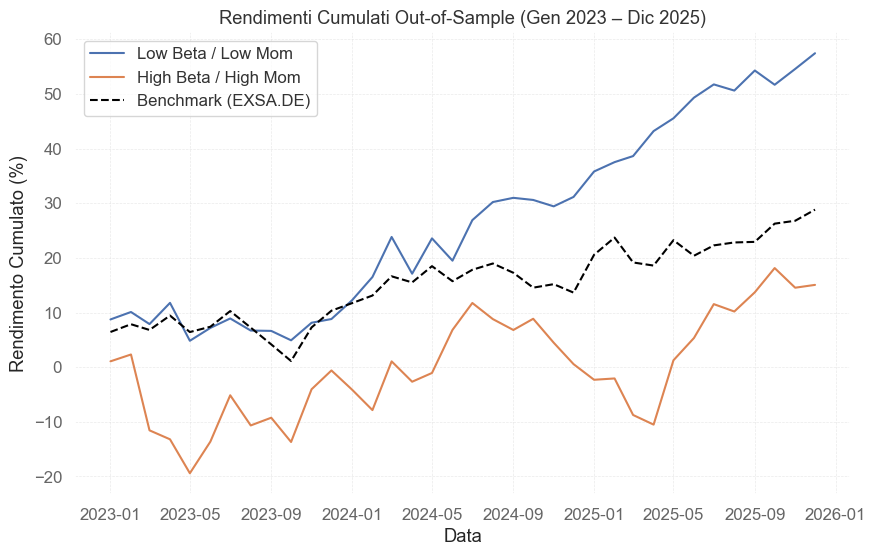

In [23]:
plt.figure(figsize=(10, 6))
plt.plot(cumulati_ptf1,    label='Low Beta / Low Mom')
plt.plot(cumulati_ptf4,    label='High Beta / High Mom')
plt.plot(cumulati_benchmark, label='Benchmark (EXSA.DE)', color='black', linestyle='--')
plt.title('Rendimenti Cumulati Out-of-Sample (Gen 2023 – Dic 2025)')
plt.xlabel('Data')
plt.ylabel('Rendimento Cumulato (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

---
## PUNTO 8 — Metriche di Performance Out-of-Sample

> **Obiettivo:** Quantificare e confrontare la performance dei due portafogli e del benchmark nel periodo Out-of-Sample attraverso le principali metriche di rischio/rendimento. 
Per ciascuna serie di rendimenti mensili utilizziamo la libreria `quantstats`, specificando `periods_per_year=12` poiché i dati sono mensili e non giornalieri — parametro fondamentale per ottenere metriche annualizzate corrette. 
Produciamo prima un report dettagliato per ciascun portafoglio a confronto con il benchmark, poi una tabella riassuntiva che mette i tre soggetti fianco a fianco per facilitare il confronto diretto.

In [24]:
r_ptf1 = serie_oos_ptf1 / 100
r_ptf4 = serie_oos_ptf4 / 100
r_bm   = rendimenti_oos_benchmark / 100

In [ ]:
print("=== Portafoglio 1 — Low Beta / Low Mom ===")
qs.reports.metrics(returns=r_ptf1, benchmark=r_bm, periods_per_year=12)

=== Portafoglio 1 — Low Beta / Low Mom ===

Parameter       Value
--------------  ---------
Benchmark       Benchmark
Risk-Free Rate  0.0%
Periods/Year    12
Compounded      Yes
Match Dates     Yes


                     Benchmark    Strategy
-------------------  -----------  ----------
Start Period         2023-01-01   2023-01-01
End Period           2025-12-01   2025-12-01
Risk-Free Rate       0.0%         0.0%
Time in Market       100.0%       100.0%

Cumulative Return    31.31%       72.98%
CAGR﹪               9.5%         20.04%

Sharpe               0.94         1.54
Prob. Sharpe Ratio   95.33%       99.27%
Sortino              1.77         2.88
Sortino/√2           1.25         2.04
Omega                1.93         2.96

Max Drawdown         -8.87%       -6.94%
Max DD Date          2023-10-01   2023-05-01
Max DD Period Start  2023-08-01   2023-05-01
Max DD Period End    2023-12-01   2023-12-01
Longest DD Days      185          215

Gain/Pain Ratio      0.93         1.96
Gain/Pa

In [28]:
print("=== Portafoglio 4 — High Beta / High Mom ===")
qs.reports.metrics(returns=r_ptf4, benchmark=r_bm, periods_per_year=12)

=== Portafoglio 4 — High Beta / High Mom ===

Parameter       Value
--------------  ---------
Benchmark       Benchmark
Risk-Free Rate  0.0%
Periods/Year    12
Compounded      Yes
Match Dates     Yes


                     Benchmark    Strategy
-------------------  -----------  ----------
Start Period         2023-01-01   2023-01-01
End Period           2025-12-01   2025-12-01
Risk-Free Rate       0.0%         0.0%
Time in Market       100.0%       100.0%

Cumulative Return    31.31%       10.3%
CAGR﹪               9.5%         3.32%

Sharpe               0.94         0.26
Prob. Sharpe Ratio   95.33%       67.44%
Sortino              1.77         0.41
Sortino/√2           1.25         0.29
Omega                1.93         1.21

Max Drawdown         -8.87%       -20.56%
Max DD Date          2023-10-01   2023-05-01
Max DD Period Start  2023-08-01   2023-03-01
Max DD Period End    2023-12-01   2024-05-01
Longest DD Days      185          428

Gain/Pain Ratio      0.93         0.21
Gain/P

In [29]:
metriche = {
    'Cumulative Return (%)': [
        qs.stats.comp(r_ptf1) * 100,
        qs.stats.comp(r_ptf4) * 100,
        qs.stats.comp(r_bm)   * 100],

    'CAGR (%)': [
        qs.stats.cagr(r_ptf1, periods=12) * 100,
        qs.stats.cagr(r_ptf4, periods=12) * 100,
        qs.stats.cagr(r_bm,   periods=12) * 100],

    'Sharpe': [
        qs.stats.sharpe(r_ptf1, periods=12),
        qs.stats.sharpe(r_ptf4, periods=12),
        qs.stats.sharpe(r_bm,   periods=12)],

    'Sortino': [
        qs.stats.sortino(r_ptf1, periods=12),
        qs.stats.sortino(r_ptf4, periods=12),
        qs.stats.sortino(r_bm,   periods=12)],

    'Volatility ann. (%)': [
        qs.stats.volatility(r_ptf1, periods=12) * 100,
        qs.stats.volatility(r_ptf4, periods=12) * 100,
        qs.stats.volatility(r_bm,   periods=12) * 100],

    'Max Drawdown (%)': [
        qs.stats.max_drawdown(r_ptf1) * 100,
        qs.stats.max_drawdown(r_ptf4) * 100,
        qs.stats.max_drawdown(r_bm)   * 100],
}

df_metriche = pd.DataFrame(
    metriche,
    index=['Low Beta / Low Mom', 'High Beta / High Mom', 'Benchmark EXSA.DE']
)

df_metriche.round(2)

,Cumulative Return (%),CAGR (%),Sharpe,Sortino,Volatility ann. (%),Max Drawdown (%)
Low Beta / Low Mom,72.98,20.04,1.54,2.88,12.43,-6.94
High Beta / High Mom,10.30,3.32,0.26,0.41,18.98,-20.56
Benchmark EXSA.DE,31.31,9.50,0.94,1.77,10.19,-8.87


## PUNTO 9 — Commento

Nel periodo Out-of-Sample (gennaio 2023 – dicembre 2025), il portafoglio **Low Beta / Low Mom** ha nettamente sovraperformato sia il benchmark che il portafoglio contrapposto. Con un rendimento cumulato del **72.98%** e un CAGR del **20.04%**, ha più che raddoppiato la performance dell'ETF EXSA.DE (31.31%, CAGR 9.5%). Anche in termini di efficienza rischio/rendimento il risultato è superiore: lo **Sharpe ratio di 1.54** si confronta con 0.94 del benchmark e 0.26 del portafoglio High Beta / High Mom, confermando che il rendimento extra non è semplicemente frutto di un maggiore rischio assunto.

Il portafoglio **High Beta / High Mom** ha invece deluso significativamente, con un rendimento cumulato di appena **10.3%** e uno Sharpe di **0.26**, entrambi ampiamente sotto il benchmark. Questo risultato è coerente con il fenomeno del *mean reversion*: i titoli che avevano corso di più nel periodo In-Sample (alto momentum) hanno faticato nel periodo successivo, mentre i titoli con basso momentum hanno beneficiato di un recupero.

Il posizionamento fattoriale sembra dunque aver generato valore rispetto alla gestione passiva, almeno per il gruppo Low Beta / Low Mom. Tuttavia è importante sottolineare che i risultati si riferiscono a un singolo campione di 150 titoli e a un orizzonte temporale di soli tre anni, elementi che non consentono di trarre conclusioni definitive sulla sistematicità di questa strategia.